# H4 · Stage 2 pierde aristas porque la pizarra y el transcript contradicen al World Model

**Hipótesis.** En el brazo B, Stage 2 recibe la respuesta correcta junto con la pizarra y el
transcript, que no contienen buena parte de esas aristas. Si el modelo "corrige" el World Model
hacia lo que ve y oye, quitar esas dos entradas debería subir el F1.

**Veredicto: cierta para Pro, falsa para Flash.** Sin pizarra ni transcript, Pro sube de
71,49 a 87,59 (+16,10, IC 95 % [+9,41, +23,02]) y deja de inventar servicios (19 → 2).
Flash no se mueve: 83,18 → 83,35.

**Lo que sigue sin explicar.** Ninguno llega a 100. Con el World Model como única entrada
Flash pierde 97 aristas y Pro 69, de las mismas clases que en H3.

## Archivos usados, cómo se generaron y dónde quedaron

| corrida | entrada de Stage 2 | cómo se generó | dónde quedó |
|---|---|---|---|
| Flash, brazo B completo | World Model oráculo + pizarra + transcript | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle oracle_gt` | `reports/ablation/2026-08-28_0315_…_oracle-oracle_gt/` |
| Flash, solo World Model | World Model oráculo | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle oracle_gt --no-transcript --no-image --model gemini-3.6-flash --out …` | `reports/pro_vs_flash/flash_gemini-3.6-flash_oracle-gt_solo-wm/` |
| Pro, brazo B completo | World Model oráculo + pizarra + transcript | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle oracle_gt --model gemini-3.1-pro-preview --out …` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt/` |
| Pro, solo World Model | World Model oráculo | `.venv/Scripts/python scripts/ablation/rerun_panel.py --prompt stage2_v6_corrected__cell9.txt --panel 30 --oracle oracle_gt --no-transcript --no-image --model gemini-3.1-pro-preview --out …` | `reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_solo-wm/` |

`--no-image` se añadió hoy a `scripts/ablation/rerun_panel.py`; el `run.json` lo registra como
`image_enabled: false`. Los logs están en `reports/pro_vs_flash/*_oracle_gt_solo_wm.log`.
Figuras de este notebook: `hipotesis/figuras/H4_*.png`.

Salvedad del diseño: el prompt de producción sigue mencionando la pizarra y el transcript
aunque no se envíen; no se tocó para que la única diferencia sean las dos entradas.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import comun as c

c.estilo()

C4 = ["B_flash", "Bwm_flash", "B_pro", "Bwm_pro"]
n, distintas = c.verificar(C4)
print(f"Control: el F1 de aristas recalculado aquí coincide con el del evaluador en {n - distintas} de {n} filas.")
c.tabla_resumen(C4)

Control: el F1 de aristas recalculado aquí coincide con el del evaluador en 120 de 120 filas.


corrida,F1 servicios,F1 aristas,aristas / GT,faltan,sobran,precisión,recall,servicios inventados,videos perfectos,carpeta
Gemini 3.6 Flash,99.70,83.18,10.00 / 12.03,86,25,91.7,76.2,1,3,reports/ablation/2026-08-28_0315_STAGE2_V6_CORRECTED_cell9_p30_oracle-oracle_gt
Gemini 3.6 Flash,99.27,83.35,9.20 / 12.03,97,12,95.7,73.1,0,7,reports/pro_vs_flash/flash_gemini-3.6-flash_oracle-gt_solo-wm
Gemini 3.1 Pro,93.54,71.49,12.63 / 12.03,95,113,70.2,73.7,19,2,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt
Gemini 3.1 Pro,99.04,87.59,10.40 / 12.03,69,20,93.6,80.9,2,14,reports/pro_vs_flash/pro_gemini-3.1-pro-preview_oracle-gt_solo-wm


## 1 · Qué le pasa a cada video al quitar la pizarra y el transcript

Una línea por video; la línea negra es la media.

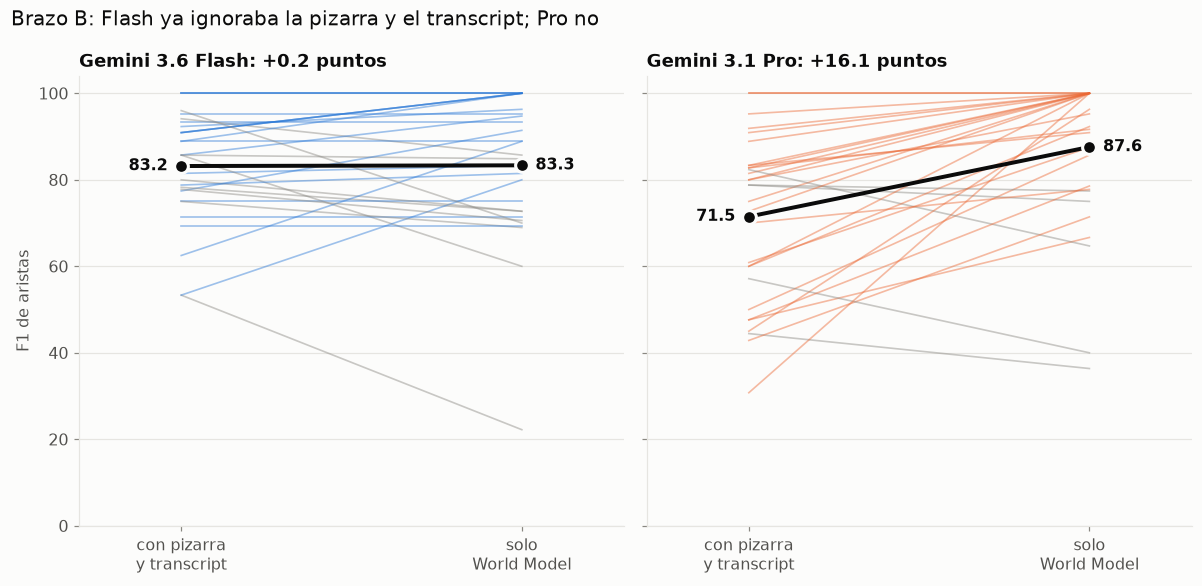

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True)
c.pendientes(ax[0], "B_flash", "Bwm_flash")
c.pendientes(ax[1], "B_pro", "Bwm_pro")
ax[0].set_ylabel("F1 de aristas")
fig.suptitle("Brazo B: Flash ya ignoraba la pizarra y el transcript; Pro no", x=0.01, ha="left", fontsize=13)
fig.tight_layout()
c.guardar(fig, "H4_pendientes")

comparación (B − A),Δ,IC 95 %,gana / pierde / empata,p (signos)
Gemini 3.6 Flash − Gemini 3.6 Flash,+0.16,"[-4.41, +4.52]",11 / 9 / 10,0.824
Gemini 3.1 Pro − Gemini 3.1 Pro,+16.10,"[+9.53, +23.03]",23 / 5 / 2,0.001
Gemini 3.1 Pro − Gemini 3.6 Flash,+4.24,"[+0.01, +8.31]",15 / 5 / 10,0.041


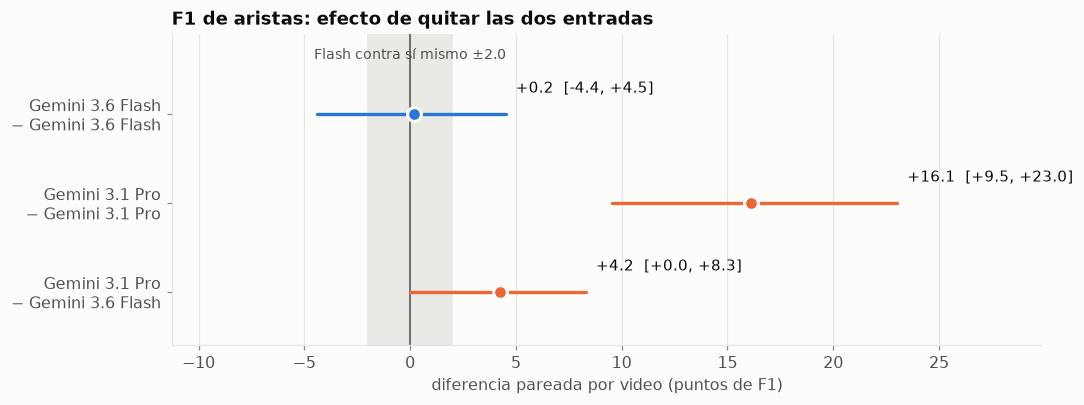

In [3]:
pares = [("B_flash", "Bwm_flash"), ("B_pro", "Bwm_pro"), ("Bwm_flash", "Bwm_pro")]
ruido = abs(c.pareado("B_flash", "B_flash_rep2")["dif"])
fig, ax = plt.subplots(figsize=(10, 3.8))
c.bosque(ax, pares, titulo="F1 de aristas: efecto de quitar las dos entradas", banda=ruido, banda_txt="Flash contra sí mismo")
fig.tight_layout()
c.guardar(fig, "H4_diferencias")
c.tabla_pareada(pares)

## 2 · Lo que Pro deja de hacer

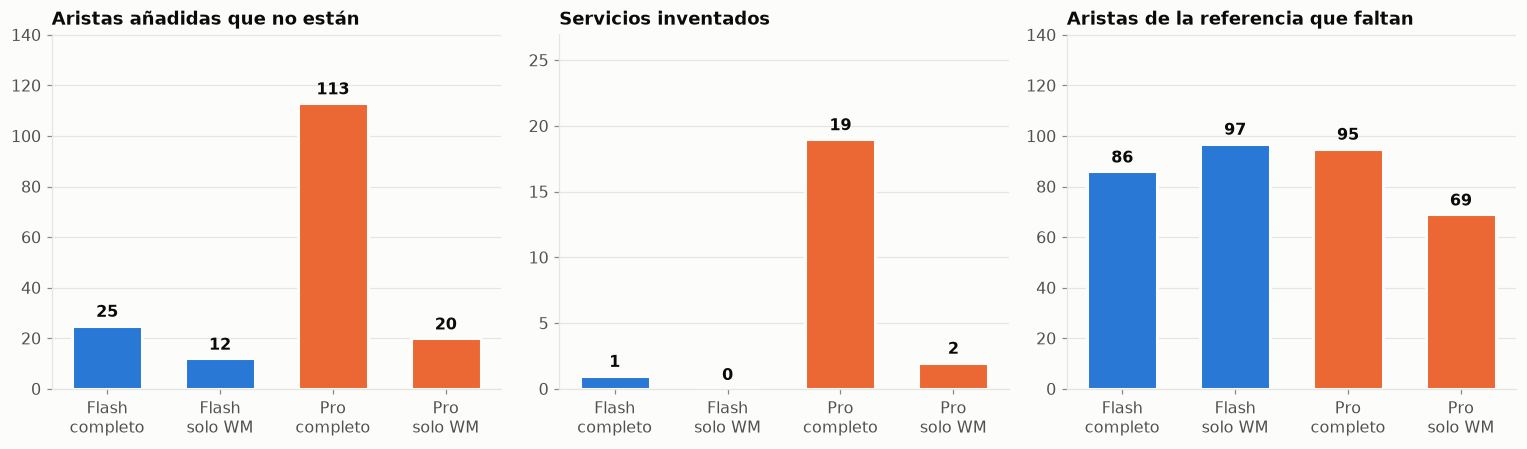

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
c.barras(ax[0], C4, "sobran", "Aristas añadidas que no están", ymax=130)
c.barras(ax[1], C4, "inventados", "Servicios inventados", ymax=25)
c.barras(ax[2], C4, "faltan", "Aristas de la referencia que faltan", ymax=130)
for a in ax:
    a.set_xticks(range(4), ["Flash\ncompleto", "Flash\nsolo WM", "Pro\ncompleto", "Pro\nsolo WM"])
fig.tight_layout()
c.guardar(fig, "H4_errores")

## 3 · El video que más sube

Con las tres entradas Pro añade servicios y aristas (en violeta); con solo el World Model los copia.

hMK2NJ-q9nc: +69.2 puntos de F1 de aristas al quitar la pizarra y el transcript


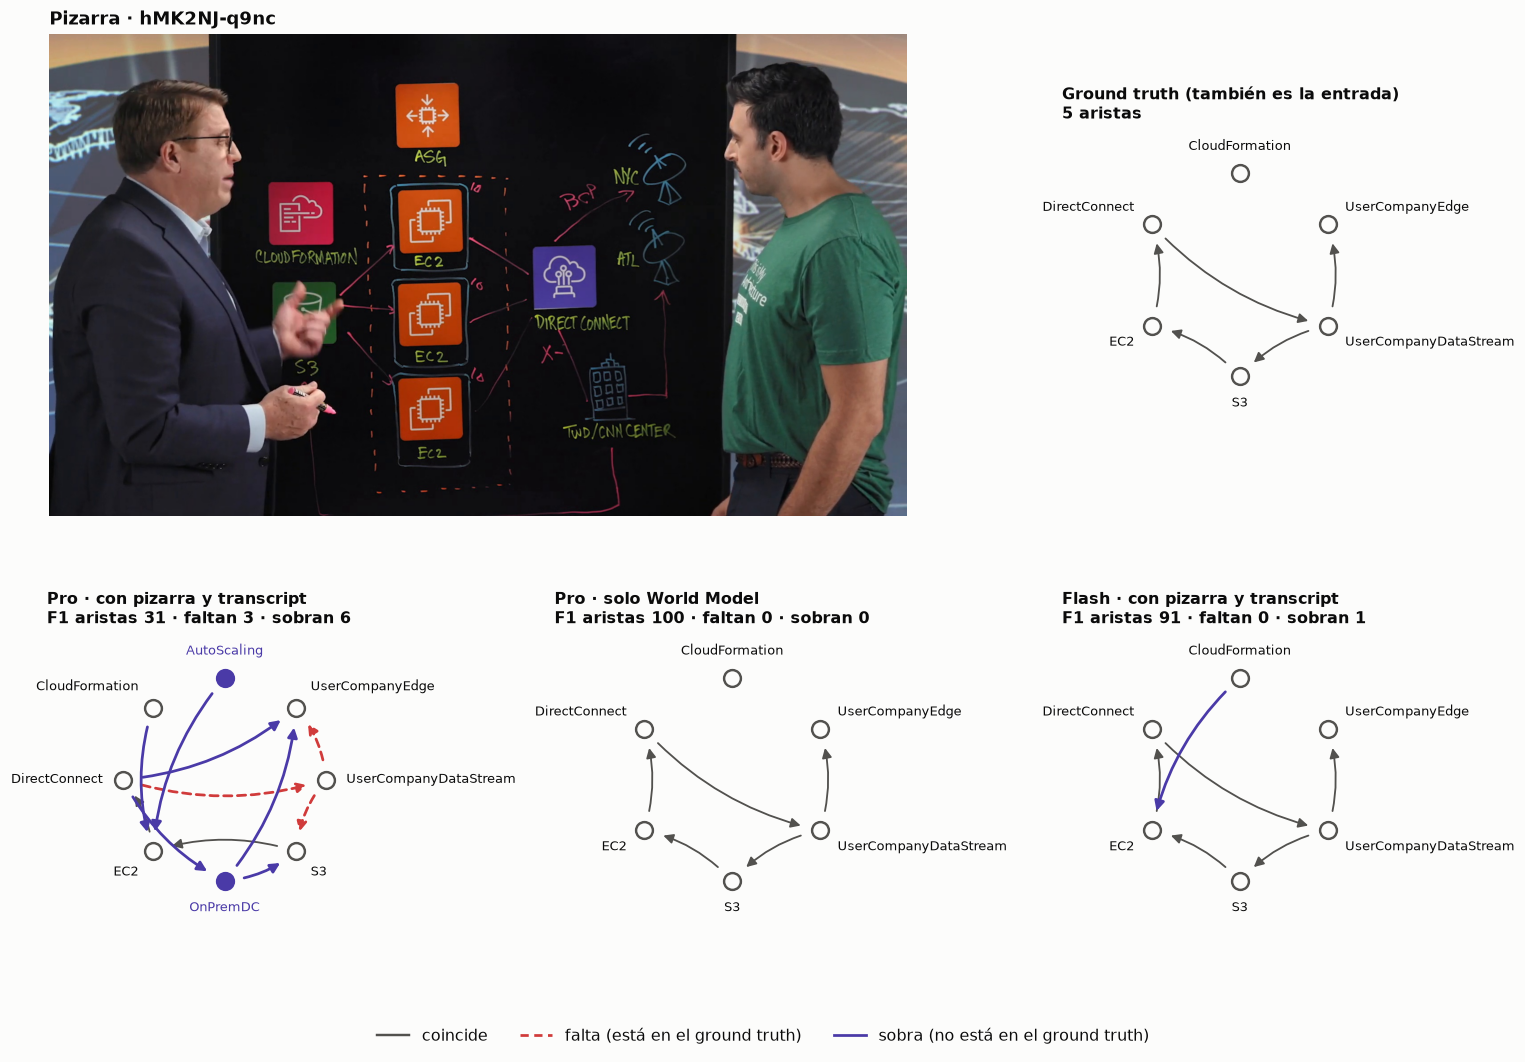

In [5]:
d = c.pareado("B_pro", "Bwm_pro")["d"]
vid = max(d, key=d.get)
print(f"{vid}: {d[vid]:+.1f} puntos de F1 de aristas al quitar la pizarra y el transcript")
fig = plt.figure(figsize=(14, 9.5))
gs = fig.add_gridspec(2, 3)
c.pizarra(fig.add_subplot(gs[0, :2]), vid)
c.grafo(fig.add_subplot(gs[0, 2]), vid, titulo="Ground truth (también es la entrada)")
c.grafo(fig.add_subplot(gs[1, 0]), vid, c.filas("B_pro")[vid], "Pro · con pizarra y transcript")
c.grafo(fig.add_subplot(gs[1, 1]), vid, c.filas("Bwm_pro")[vid], "Pro · solo World Model")
c.grafo(fig.add_subplot(gs[1, 2]), vid, c.filas("B_flash")[vid], "Flash · con pizarra y transcript")
c.leyenda_grafo(fig)
fig.tight_layout()
c.guardar(fig, "H4_ejemplo")

## Qué aporta al paper

Separa dos pérdidas que estaban mezcladas en el brazo B. Una depende del modelo: Pro reescribe
la respuesta correcta cuando la pizarra y la narración dicen otra cosa, y eso encaja con la
tesis de que la topología de la referencia no está en la pizarra. La otra es de fondo: de 12 a
17 puntos que se pierden aunque no haya nada que contradiga al World Model.